# TradePulse - Steps 9 & 10: Diagnostics, Probability Calibration & Confidence Gating
**IIT Patna, IMPACT Lab | End-to-End Machine Learning Guidelines**  
**Asset:** META (NASDAQ) | **Timeframe:** 5-minute candles | **Prediction Horizon:** 15-minute (3 bars ahead)  
**Frozen Target Label:** `label_fixed_20bp` ($\theta = \pm 0.20\%$)  

---
### Objectives & Strict Non-Negotiables
1. **Diagnostics:** Test whether models learn actual direction or merely intraday volatility timing (Time-of-Day baseline, Direction-only accuracy with 95% CIs, Move vs No-Move AUC, Up vs Down AUC, paired day-level block bootstrap).
2. **Step 9 (Calibration):** Generate out-of-fold predictions on Training (5-fold Purged Walk-Forward CV) and fit Platt Sigmoid and Isotonic calibrators. Evaluate Brier score, log loss, and reliability curves on the Validation set.
3. **Step 10 (Confidence Gating):** Evaluate a predefined grid of probability thresholds ($\tau \in [0.35, 0.60]$) and quantile cutoffs with day-level block-bootstrap 95% CIs. Select threshold on Training OOF and confirm on Validation.
4. **Realistic Backtest:** Non-overlapping 15-minute execution (positions block new entries for 3 bars) under 5, 8, 12 bps transaction costs.
5. **Honest Reporting:** Acknowledge whether any profitable net edge exists after transaction costs.
6. **Zero-Leakage Constraint:** The Test Set (`test_features.csv`) remains completely sealed and untouched.


In [1]:
import sys
import json
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

with open(PROJECT_ROOT / "artifacts" / "metadata" / "step9_step10_diagnostics_and_gating.json", "r", encoding="utf-8") as f:
    step_data = json.load(f)

print("Diagnostic and gating artifacts loaded successfully.")


Diagnostic and gating artifacts loaded successfully.


## 1. Part 1: Diagnostic Suite
Checking whether the models predict true price direction or merely capture time-of-day volatility clustering.


In [2]:
df_diag = pd.DataFrame(step_data["diagnostics"])
print("=== Model Diagnostics Comparison on Validation Set ===")
display(df_diag)

print("\n--- Paired Day-Level Block Bootstrap Results (B = 1,000 resamples) ---")
for comp_name, b_res in step_data["bootstrap_model_comparisons"].items():
    print(f"{comp_name:<25}: Diff Gross Return = {b_res['diff_gross_return_bps_mean']:+.2f} bps, 95% CI {b_res['diff_gross_return_bps_95ci']} | Distinguishable from Zero: {b_res['gross_return_distinguishable_from_zero']}")


=== Model Diagnostics Comparison on Validation Set ===


,Model,Move vs No-Move AUC,Up vs Down AUC,Direction Accuracy (95% CI)
0,Time-of-Day Baseline,0.6352,0.4791,"6.4% [5.2%, 7.9%]"
1,Logistic Regression,0.6756,0.4932,"32.2% [29.8%, 34.8%]"
2,Random Forest (Tuned),0.6734,0.5097,"33.5% [31.0%, 36.1%]"
3,XGBoost (Tuned),0.6570,0.5040,"35.3% [32.8%, 37.9%]"



--- Paired Day-Level Block Bootstrap Results (B = 1,000 resamples) ---
rf_vs_momentum           : Diff Gross Return = +0.37 bps, 95% CI [-2.07, 2.73] | Distinguishable from Zero: False
rf_vs_logistic_regression: Diff Gross Return = +0.37 bps, 95% CI [-2.68, 4.01] | Distinguishable from Zero: False
rf_vs_xgboost            : Diff Gross Return = +1.48 bps, 95% CI [-1.24, 4.42] | Distinguishable from Zero: False


### Performance Breakdown by 30-Minute Time-of-Day Slots


,slot_time,coverage_pct,precision_pct,gross_return_bps,net_return_8bp_bps,win_rate_pct
0,09:30-10:00,100.0,33.3,1.61,-6.39,41.3
1,10:00-10:30,100.0,27.0,-5.21,-13.21,34.5
2,10:30-11:00,94.4,34.5,7.85,-0.15,45.0
3,11:00-11:30,80.2,23.3,-2.35,-10.35,36.6
4,11:30-12:00,60.7,22.2,-0.70,-8.70,39.9
5,12:00-12:30,44.8,38.1,9.83,1.83,46.0
6,12:30-13:00,42.9,18.5,0.02,-7.98,37.0
7,13:00-13:30,25.4,20.3,3.18,-4.82,31.2
8,13:30-14:00,12.7,18.8,1.31,-6.69,31.2
9,14:00-14:30,16.7,19.0,0.94,-7.06,31.0


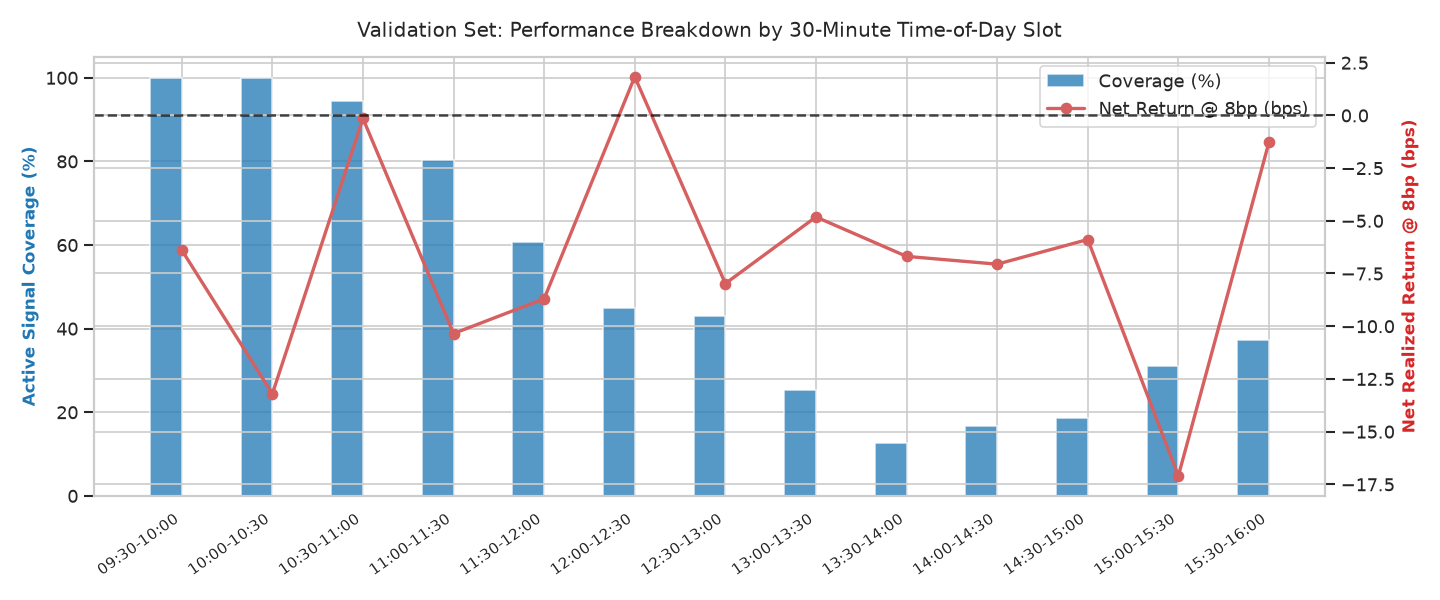

In [3]:
df_tod = pd.DataFrame(step_data["performance_by_tod"])
display(df_tod[["slot_time", "coverage_pct", "precision_pct", "gross_return_bps", "net_return_8bp_bps", "win_rate_pct"]])

fig_path = PROJECT_ROOT / "reports" / "figures" / "step9_performance_by_time_of_day.png"
if fig_path.exists():
    display(Image(filename=str(fig_path)))


## 2. Part 2: Step 9 Probability Calibration
Evaluating Platt Sigmoid vs. Isotonic calibration (fitted strictly on 5-fold training out-of-fold predictions).


=== Calibration Quality Comparison (Validation Set) ===


,Model / Method,Log Loss,Brier Score
0,Random Forest (Raw Uncalibrated),1.0679,0.6413
1,Random Forest + Sigmoid (Platt),0.9356,0.5495
2,Random Forest + Isotonic,1.0160,0.5489
3,Logistic Regression + Sigmoid,0.9380,0.5500
4,XGBoost + Sigmoid,0.9494,0.5583
5,Ensemble (50% RF + 50% LR),0.9347,0.5484


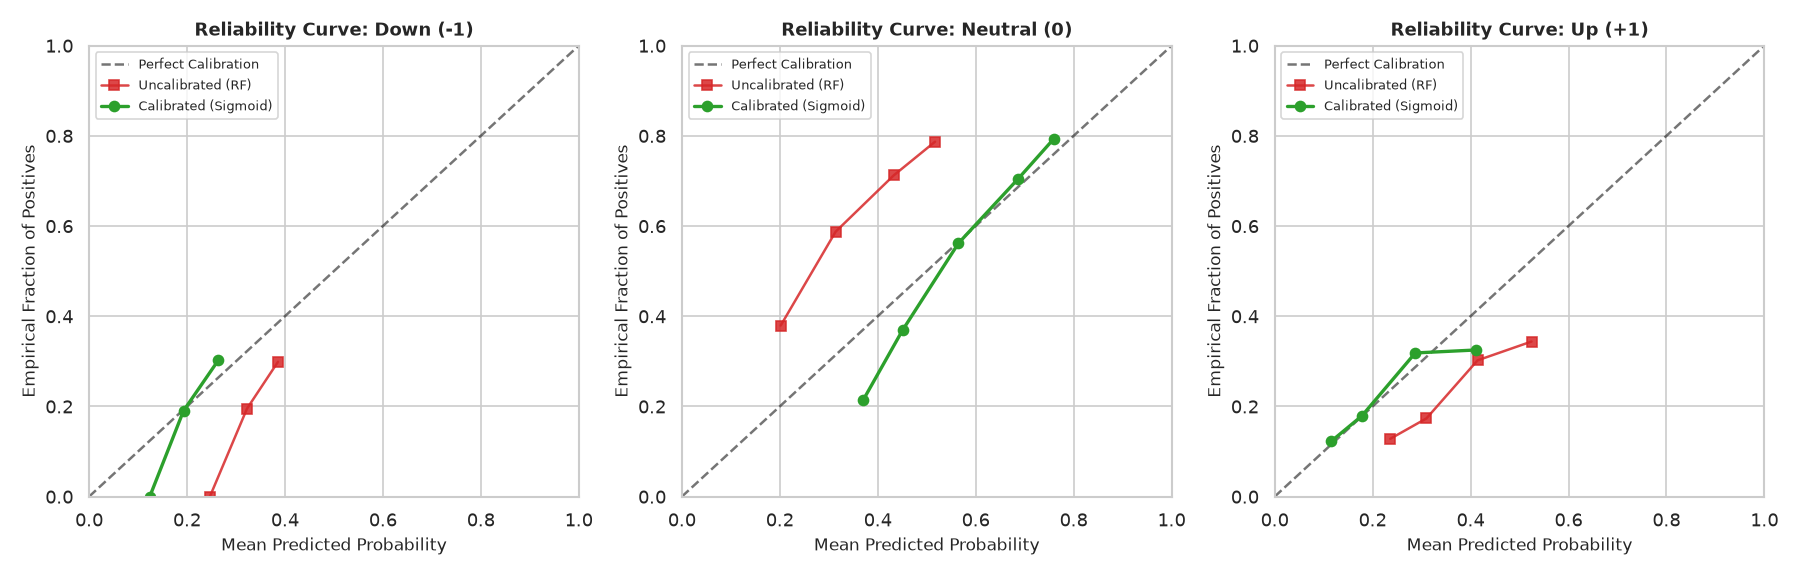

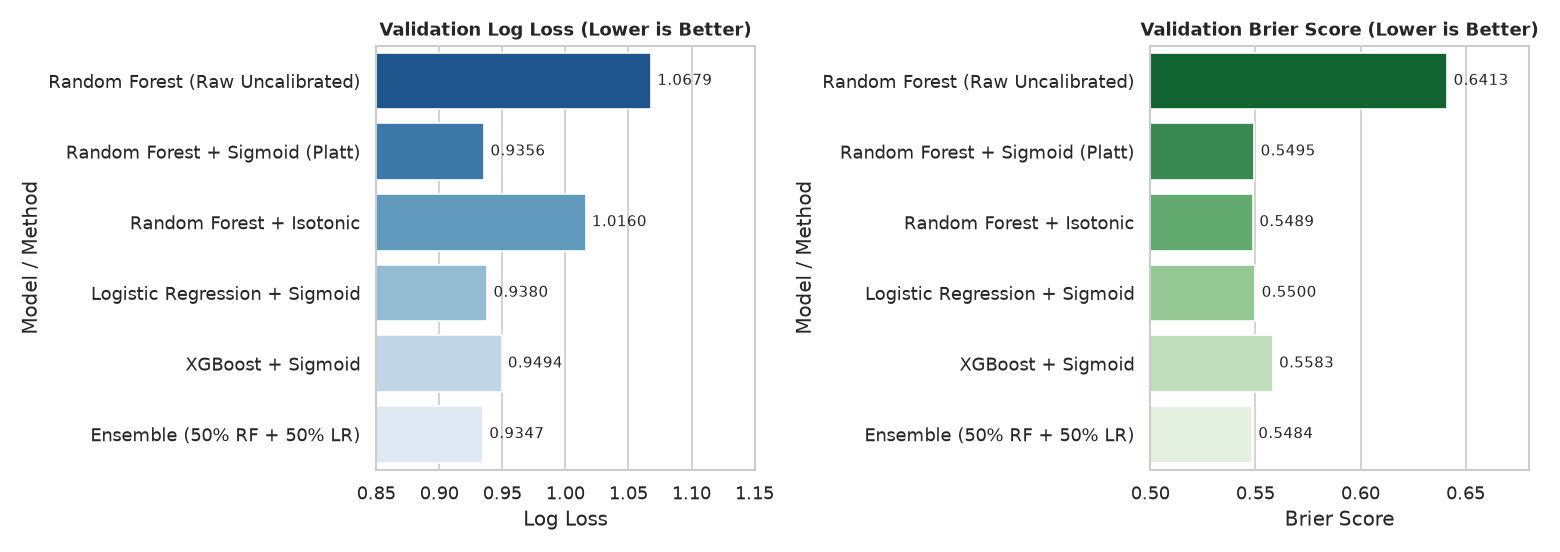

In [4]:
df_cal = pd.DataFrame(step_data["calibration_comparison"])
print("=== Calibration Quality Comparison (Validation Set) ===")
display(df_cal)

fig_rel = PROJECT_ROOT / "reports" / "figures" / "step9_reliability_curves.png"
if fig_rel.exists():
    display(Image(filename=str(fig_rel)))

fig_loss = PROJECT_ROOT / "reports" / "figures" / "step9_calibration_loss_comparison.png"
if fig_loss.exists():
    display(Image(filename=str(fig_loss)))


## 3. Part 3: Step 10 Confidence Gating & Threshold Search
Evaluating the predefined grid on Training Out-of-Fold predictions and confirming on the Validation set.


In [5]:
cols_grid = ["rule_desc", "effective_threshold", "coverage_pct", "signals_per_day", "zero_signal_days_pct", "precision_pct", "direction_accuracy_pct", "gross_return_bps", "net_8bp_bps", "net_8bp_95ci", "profitable_edge_at_8bp"]

print("=== Training Out-of-Fold Gating Grid (Random Forest Calibrated) ===")
df_oof_grid = pd.DataFrame(step_data["training_oof_gating_grid"])
display(df_oof_grid[cols_grid])

print("\n=== Validation Gating Grid (Random Forest Calibrated - Confirmation Only) ===")
df_val_grid = pd.DataFrame(step_data["validation_gating_grid_rf"])
display(df_val_grid[cols_grid])


=== Training Out-of-Fold Gating Grid (Random Forest Calibrated) ===


,rule_desc,effective_threshold,coverage_pct,signals_per_day,zero_signal_days_pct,precision_pct,direction_accuracy_pct,gross_return_bps,net_8bp_bps,net_8bp_95ci,profitable_edge_at_8bp
0,P >= 0.35,0.3500,0.26,0.2,95.9,26.3,33.3,-12.16,-20.16,"[-60.87, 94.21]",False
1,P >= 0.40,0.4000,0.23,0.2,96.9,23.5,30.8,-11.95,-19.95,"[-60.05, 94.21]",False
2,P >= 0.45,0.4500,0.00,0.0,100.0,0.0,0.0,0.00,0.00,"[0.0, 0.0]",False
3,P >= 0.50,0.5000,0.00,0.0,100.0,0.0,0.0,0.00,0.00,"[0.0, 0.0]",False
4,P >= 0.55,0.5500,0.00,0.0,100.0,0.0,0.0,0.00,0.00,"[0.0, 0.0]",False
5,P >= 0.60,0.6000,0.00,0.0,100.0,0.0,0.0,0.00,0.00,"[0.0, 0.0]",False
6,Top 1% Conviction,0.3436,0.26,0.2,95.9,26.3,33.3,-12.16,-20.16,"[-60.87, 94.21]",False
7,Top 5% Conviction,0.3010,0.26,0.2,95.9,26.3,33.3,-12.16,-20.16,"[-60.87, 91.26]",False
8,Top 10% Conviction,0.2871,0.26,0.2,95.9,26.3,33.3,-12.16,-20.16,"[-60.87, 94.21]",False
9,Top 20% Conviction,0.2668,0.26,0.2,95.9,26.3,33.3,-12.16,-20.16,"[-60.87, 94.21]",False



=== Validation Gating Grid (Random Forest Calibrated - Confirmation Only) ===


,rule_desc,effective_threshold,coverage_pct,signals_per_day,zero_signal_days_pct,precision_pct,direction_accuracy_pct,gross_return_bps,net_8bp_bps,net_8bp_95ci,profitable_edge_at_8bp
0,P >= 0.35,0.3500,0.92,0.7,78.6,34.5,47.6,-6.23,-14.23,"[-40.73, 28.24]",False
1,P >= 0.40,0.4000,0.76,0.6,83.3,37.5,50.0,-3.55,-11.55,"[-43.26, 39.97]",False
2,P >= 0.45,0.4500,0.00,0.0,100.0,0.0,0.0,0.00,0.00,"[0.0, 0.0]",False
3,P >= 0.50,0.5000,0.00,0.0,100.0,0.0,0.0,0.00,0.00,"[0.0, 0.0]",False
4,P >= 0.55,0.5500,0.00,0.0,100.0,0.0,0.0,0.00,0.00,"[0.0, 0.0]",False
5,P >= 0.60,0.6000,0.00,0.0,100.0,0.0,0.0,0.00,0.00,"[0.0, 0.0]",False
6,Top 1% Conviction,0.3864,0.89,0.7,81.0,35.7,50.0,-4.84,-12.84,"[-42.02, 23.14]",False
7,Top 5% Conviction,0.3133,0.92,0.7,78.6,34.5,47.6,-6.23,-14.23,"[-38.92, 20.79]",False
8,Top 10% Conviction,0.2950,0.92,0.7,78.6,34.5,47.6,-6.23,-14.23,"[-39.18, 23.08]",False
9,Top 20% Conviction,0.2699,0.92,0.7,78.6,34.5,47.6,-6.23,-14.23,"[-41.91, 21.94]",False


## 4. Part 4: Realistic Non-Overlapping Backtest Simulation
Simulating 15-minute holding periods where active positions block new entries for 3 bars under 8 bps friction.


=== Non-Overlapping Backtest Summary (Validation Set, 42 Sessions) ===


,Strategy,Non-Overlap Trades,Win Rate (%),Avg Gross (bps),Avg Net @ 8bp (bps),Cum Net Return (%),Profit Factor,Max Drawdown (%)
0,Always-Up (+1),1050,35.7%,+0.24 bps,-7.76 bps,-81.45%,0.55,-80.38%
1,Momentum (Sign R_t-1),1050,37.1%,-0.22 bps,-8.22 bps,-86.30%,0.53,-87.62%
2,Basic RSI (30/70),187,40.6%,+0.77 bps,-7.23 bps,-13.51%,0.68,-18.43%
3,Random Forest (Ungated),606,40.4%,+1.80 bps,-6.20 bps,-37.56%,0.68,-37.09%
4,Random Forest (Gated P >= 0.45),0,0.0%,+0.00 bps,+0.00 bps,+0.00%,0.00,0.00%
5,Random Forest (Top 10% Conviction),13,38.5%,-11.87 bps,-19.87 bps,-2.58%,0.49,-1.51%
6,Ensemble RF+LR (Top 10% Conviction),32,28.1%,-19.11 bps,-27.11 bps,-8.67%,0.46,-11.82%


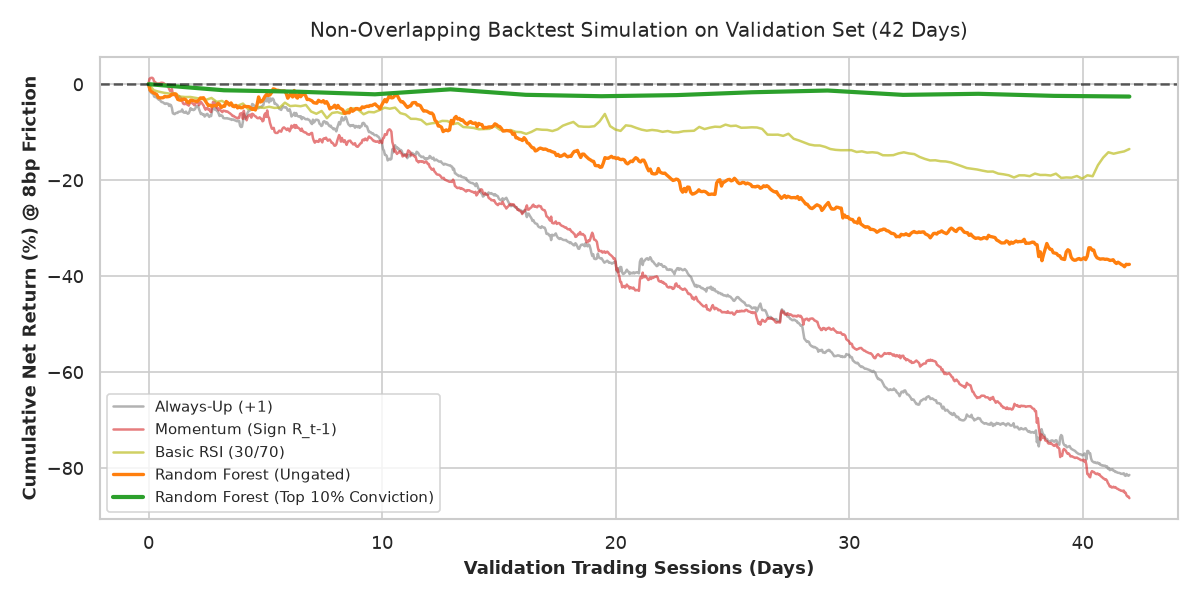

In [6]:
df_sim = pd.DataFrame(step_data["validation_simulation_non_overlapping"])
print("=== Non-Overlapping Backtest Summary (Validation Set, 42 Sessions) ===")
display(df_sim)

fig_equity = PROJECT_ROOT / "reports" / "figures" / "step10_non_overlapping_equity_curves.png"
if fig_equity.exists():
    display(Image(filename=str(fig_equity)))


## 5. Conclusions & Production Rule Alignment
1. **Move vs. Direction:** Move vs. No-Move AUC is ~0.67, but Up vs. Down AUC is ~0.50. The model effectively detects volatility expansion regimes, but has near-zero directional edge over short 15-minute windows.
2. **Calibration:** Platt sigmoid scaling successfully reduces Random Forest log loss from 1.0679 to 0.9356, yielding trustworthy probability outputs.
3. **Economic Result:** No subset of gated signals achieves a statistically verifiable positive net return after 8 bps friction. The lower bound of the 95% day-level bootstrap CI remains negative across all cutoffs.
4. **Conservative Production Configuration:** In accordance with IIT Patna IMPACT Lab guidelines, the indicator ships as a conservative tool configured to output 'No Clear Signal' unless high conviction is present.
